In [1]:
import sys
print(sys.executable)

c:\Users\Lenovo\projects\uk-power-pipeline\.venv\Scripts\python.exe


In [2]:
import json
import requests

BASE_URL = "https://data.elexon.co.uk/bmrs/api/v1"
date = "2026-10-05"

url = f"{BASE_URL}/balancing/settlement/system-prices/{date}"
response = requests.get(url, params={"format": "json"}, timeout=30)

print("Status code:", response.status_code)
body = response.json()
print("Top level keys:", list(body.keys()))
print("Metadata:", body.get("metadata"))

records = body["data"]
print("Number of records:", len(records))
print("Fields in a record:", list(records[0].keys()))
print()
print("First record:")
print(json.dumps(records[0], indent=2))

Status code: 200
Top level keys: ['metadata', 'data']
Metadata: {'datasets': ['DISEBSP']}
Number of records: 48
Fields in a record: ['settlementDate', 'settlementPeriod', 'startTime', 'createdDateTime', 'systemSellPrice', 'systemBuyPrice', 'bsadDefaulted', 'priceDerivationCode', 'reserveScarcityPrice', 'netImbalanceVolume', 'sellPriceAdjustment', 'buyPriceAdjustment', 'replacementPrice', 'replacementPriceReferenceVolume', 'totalAcceptedOfferVolume', 'totalAcceptedBidVolume', 'totalAdjustmentSellVolume', 'totalAdjustmentBuyVolume', 'totalSystemTaggedAcceptedOfferVolume', 'totalSystemTaggedAcceptedBidVolume', 'totalSystemTaggedAdjustmentSellVolume', 'totalSystemTaggedAdjustmentBuyVolume']

First record:
{
  "settlementDate": "2026-10-05",
  "settlementPeriod": 1,
  "startTime": "2026-10-04T23:00:00Z",
  "createdDateTime": "2026-10-05T23:44:39Z",
  "systemSellPrice": 143.92,
  "systemBuyPrice": 143.92,
  "bsadDefaulted": false,
  "priceDerivationCode": "P",
  "reserveScarcityPrice": 0.0,


In [3]:
from datetime import datetime

for r in records:
    start = datetime.fromisoformat(r["startTime"].replace("Z", "+00:00"))
    created = datetime.fromisoformat(r["createdDateTime"].replace("Z", "+00:00"))
    lag_hours = (created - start).total_seconds() / 3600
    print(f"Period {r['settlementPeriod']:>2} | start {r['startTime']} | created {r['createdDateTime']} | lag {lag_hours:6.1f} h")

Period  1 | start 2026-10-04T23:00:00Z | created 2026-10-05T23:44:39Z | lag   24.7 h
Period  2 | start 2026-10-04T23:30:00Z | created 2026-10-06T00:14:41Z | lag   24.7 h
Period  3 | start 2026-10-05T00:00:00Z | created 2026-10-06T00:44:42Z | lag   24.7 h
Period  4 | start 2026-10-05T00:30:00Z | created 2026-10-06T01:14:36Z | lag   24.7 h
Period  5 | start 2026-10-05T01:00:00Z | created 2026-10-06T01:44:42Z | lag   24.7 h
Period  6 | start 2026-10-05T01:30:00Z | created 2026-10-06T02:16:41Z | lag   24.8 h
Period  7 | start 2026-10-05T02:00:00Z | created 2026-10-06T02:44:44Z | lag   24.7 h
Period  8 | start 2026-10-05T02:30:00Z | created 2026-10-06T03:14:42Z | lag   24.7 h
Period  9 | start 2026-10-05T03:00:00Z | created 2026-10-06T03:44:35Z | lag   24.7 h
Period 10 | start 2026-10-05T03:30:00Z | created 2026-10-06T04:14:37Z | lag   24.7 h
Period 11 | start 2026-10-05T04:00:00Z | created 2026-10-06T04:44:34Z | lag   24.7 h
Period 12 | start 2026-10-05T04:30:00Z | created 2026-10-06T05:14

In [4]:
from pathlib import Path

def fetch_system_prices(date: str) -> dict:
    url = f"{BASE_URL}/balancing/settlement/system-prices/{date}"
    resp = requests.get(url, params={"format": "json"}, timeout=30)
    resp.raise_for_status()
    return resp.json()

date = "2026-10-06"
body = fetch_system_prices(date)
records = body["data"]
print("Records:", len(records))

for r in records:
    start = datetime.fromisoformat(r["startTime"].replace("Z", "+00:00"))
    created = datetime.fromisoformat(r["createdDateTime"].replace("Z", "+00:00"))
    lag_hours = (created - start).total_seconds() / 3600
    print(f"Period {r['settlementPeriod']:>2} | price {r['systemSellPrice']:>8} | created {r['createdDateTime']} | lag {lag_hours:6.1f} h")

# Save the raw response so we can compare it with a later fetch
probe_dir = Path("../data/probe")
probe_dir.mkdir(parents=True, exist_ok=True)
fetched_at = datetime.utcnow().strftime("%Y%m%dT%H%M%SZ")
out_file = probe_dir / f"system_prices_{date}_fetched_{fetched_at}.json"
out_file.write_text(json.dumps(body, indent=2))
print("Saved to", out_file.resolve())

Records: 48
Period  1 | price    139.0 | created 2026-10-06T23:44:36Z | lag   24.7 h
Period  2 | price    141.0 | created 2026-10-07T00:14:39Z | lag   24.7 h
Period  3 | price 141.91425719742062 | created 2026-10-07T00:44:37Z | lag   24.7 h
Period  4 | price    141.0 | created 2026-10-07T01:14:40Z | lag   24.7 h
Period  5 | price    140.0 | created 2026-10-07T01:44:39Z | lag   24.7 h
Period  6 | price   141.96 | created 2026-10-07T02:17:08Z | lag   24.8 h
Period  7 | price   140.23 | created 2026-10-07T02:45:01Z | lag   24.8 h
Period  8 | price    131.1 | created 2026-10-07T03:14:40Z | lag   24.7 h
Period  9 | price    148.5 | created 2026-10-06T03:48:35Z | lag    0.8 h
Period 10 | price    148.5 | created 2026-10-06T04:18:33Z | lag    0.8 h
Period 11 | price   185.12 | created 2026-10-06T04:48:23Z | lag    0.8 h
Period 12 | price   186.86 | created 2026-10-06T05:18:25Z | lag    0.8 h
Period 13 | price    188.5 | created 2026-10-06T05:48:27Z | lag    0.8 h
Period 14 | price   219.06 | 

In [5]:
spec = requests.get("https://data.elexon.co.uk/swagger/v1/swagger.json", timeout=60).json()
print("Total endpoints:", len(spec["paths"]))

keywords = ["fuelhh", "indo", "itsdo", "demand", "wind", "solar", "agws", "dgws"]
for path, ops in spec["paths"].items():
    if any(k in path.lower() for k in keywords):
        op = ops.get("get", {})
        params = [p["name"] for p in op.get("parameters", [])]
        print(f"{path}\n    {op.get('summary')}\n    params: {params}\n")

Total endpoints: 322
/datasets/FUELHH
    Half-hourly generation outturn by fuel type (FUELHH)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'settlementDateFrom', 'settlementDateTo', 'settlementPeriod', 'fuelType', 'format']

/datasets/FUELHH/stream
    Half-hourly generation outturn by fuel type (FUELHH) stream
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'settlementDateFrom', 'settlementDateTo', 'settlementPeriod', 'fuelType']

/datasets/WINDFOR
    Wind generation forecast (WINDFOR)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'format']

/datasets/WINDFOR/stream
    Wind generation forecast (WINDFOR) stream
    params: ['publishDateTimeFrom', 'publishDateTimeTo']

/datasets/INDO
    Initial National Demand outturn (INDO)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'format']

/datasets/INDOD
    Initial National Demand outturn daily (INDOD)
    params: ['publishDateTimeFrom', 'publishDateTimeTo', 'format']

/datasets/INDOD/stream
    In

In [6]:
url = f"{BASE_URL}/datasets/FUELHH"
params = {"settlementDateFrom": "2026-10-05", "settlementDateTo": "2026-10-05", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
fuel = body["data"]
print("Number of records:", len(fuel))
print("Fields:", list(fuel[0].keys()))
print()
print("First record:")
print(json.dumps(fuel[0], indent=2))
print()
print("Fuel types:", sorted({r["fuelType"] for r in fuel}))
print("Distinct periods:", len({r["settlementPeriod"] for r in fuel}))

Status: 200
Top level keys: ['data']
Number of records: 960
Fields: ['dataset', 'publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'fuelType', 'generation']

First record:
{
  "dataset": "FUELHH",
  "publishTime": "2026-10-05T23:00:00Z",
  "startTime": "2026-10-05T22:30:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 48,
  "fuelType": "BIOMASS",
  "generation": 3118
}

Fuel types: ['BIOMASS', 'CCGT', 'COAL', 'INTELEC', 'INTEW', 'INTFR', 'INTGRNL', 'INTIFA2', 'INTIRL', 'INTNED', 'INTNEM', 'INTNSL', 'INTVKL', 'NPSHYD', 'NUCLEAR', 'OCGT', 'OIL', 'OTHER', 'PS', 'WIND']
Distinct periods: 48


In [7]:
url = f"{BASE_URL}/demand/outturn"
params = {"settlementDateFrom": "2026-10-05", "settlementDateTo": "2026-10-05", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
demand = body["data"]
print("Number of records:", len(demand))
print("Fields:", list(demand[0].keys()))
print()
print("First record:")
print(json.dumps(demand[0], indent=2))
print()
print("Distinct periods:", len({r["settlementPeriod"] for r in demand}))

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 48
Fields: ['publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'initialDemandOutturn', 'initialTransmissionSystemDemandOutturn']

First record:
{
  "publishTime": "2026-10-04T23:30:00Z",
  "startTime": "2026-10-04T23:00:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 1,
  "initialDemandOutturn": 19809,
  "initialTransmissionSystemDemandOutturn": 23607
}

Distinct periods: 48


In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path
import requests

BASE_URL = "https://data.elexon.co.uk/bmrs/api/v1"
date = "2026-10-06"
probe_dir = Path("../data/probe")

# 1. Fetch the same date again and save it with a new timestamp
resp = requests.get(
    f"{BASE_URL}/balancing/settlement/system-prices/{date}",
    params={"format": "json"},
    timeout=30,
)
resp.raise_for_status()
fetched_at = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
new_file = probe_dir / f"system_prices_{date}_fetched_{fetched_at}.json"
new_file.write_text(json.dumps(resp.json(), indent=2))

# 2. Load the earliest and latest saved fetches for this date
files = sorted(probe_dir.glob(f"system_prices_{date}_fetched_*.json"))
print("Saved fetches:", [f.name for f in files])
old = {r["settlementPeriod"]: r for r in json.loads(files[0].read_text())["data"]}
new = {r["settlementPeriod"]: r for r in json.loads(files[-1].read_text())["data"]}

# 3. Compare period by period
changed = []
for p in sorted(new):
    o, n = old[p], new[p]
    version_changed = o["createdDateTime"] != n["createdDateTime"]
    diff = n["systemSellPrice"] - o["systemSellPrice"]
    if version_changed:
        changed.append(abs(diff))
    print(f"Period {p:>2} | old {o['systemSellPrice']:>9.2f} | new {n['systemSellPrice']:>9.2f} "
          f"| diff {diff:>8.2f} | new version: {version_changed}")

print()
print("Periods with a new version:", len(changed))
print("Of those, price actually changed:", sum(1 for d in changed if d > 0.005))
if changed:
    print("Average absolute change (£/MWh):", round(sum(changed) / len(changed), 2))
    print("Largest absolute change (£/MWh):", round(max(changed), 2))

Saved fetches: ['system_prices_2026-10-06_fetched_20261007T031832Z.json', 'system_prices_2026-10-06_fetched_20261007T223608Z.json']
Period  1 | old    139.00 | new    139.00 | diff     0.00 | new version: False
Period  2 | old    141.00 | new    141.00 | diff     0.00 | new version: False
Period  3 | old    141.91 | new    141.91 | diff     0.00 | new version: False
Period  4 | old    141.00 | new    141.00 | diff     0.00 | new version: False
Period  5 | old    140.00 | new    140.00 | diff     0.00 | new version: False
Period  6 | old    141.96 | new    141.96 | diff     0.00 | new version: False
Period  7 | old    140.23 | new    140.23 | diff     0.00 | new version: False
Period  8 | old    131.10 | new    131.10 | diff     0.00 | new version: False
Period  9 | old    148.50 | new    148.50 | diff     0.00 | new version: True
Period 10 | old    148.50 | new    148.50 | diff     0.00 | new version: True
Period 11 | old    185.12 | new    185.12 | diff     0.00 | new version: True
Pe

In [2]:
from collections import Counter

field_changes = Counter()
for p in new:
    if old[p]["createdDateTime"] == new[p]["createdDateTime"]:
        continue
    for field in new[p]:
        if field == "createdDateTime":
            continue
        if old[p].get(field) != new[p].get(field):
            field_changes[field] += 1

if field_changes:
    print("Fields that changed in republished records:")
    for field, count in field_changes.most_common():
        print(f"  {field}: {count} periods")
else:
    print("No fields changed apart from createdDateTime")

No fields changed apart from createdDateTime


In [3]:
url = f"{BASE_URL}/generation/actual/per-type/wind-and-solar"
params = {
    "from": "2026-10-05",
    "to": "2026-10-05",
    "settlementPeriodFrom": 1,
    "settlementPeriodTo": 50,
    "format": "json",
}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
ws = body["data"]
print("Number of records:", len(ws))
print("Fields:", list(ws[0].keys()))
print()
print("First record:")
print(json.dumps(ws[0], indent=2))
print()
for field in ["psrType", "businessType", "settlementDate"]:
    if field in ws[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in ws}))
print("Distinct periods:", len({r["settlementPeriod"] for r in ws}))

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 144
Fields: ['publishTime', 'businessType', 'psrType', 'quantity', 'startTime', 'settlementDate', 'settlementPeriod']

First record:
{
  "publishTime": "2026-10-06T01:00:01Z",
  "businessType": "Wind generation",
  "psrType": "Wind Onshore",
  "quantity": 1810.0,
  "startTime": "2026-10-05T22:30:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 48
}

Distinct psrType: ['Solar', 'Wind Offshore', 'Wind Onshore']
Distinct businessType: ['Solar generation', 'Wind generation']
Distinct settlementDate: ['2026-10-05']
Distinct periods: 48


In [4]:
from datetime import datetime

url = f"{BASE_URL}/forecast/demand/day-ahead/earliest"
params = {"from": "2026-10-05", "to": "2026-10-06", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
fc = body["data"]
print("Number of records:", len(fc))
print("Fields:", list(fc[0].keys()))
print()
print("First record:")
print(json.dumps(fc[0], indent=2))
print()
for field in ["boundary", "settlementDate"]:
    if field in fc[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in fc}))

def to_dt(s):
    return datetime.fromisoformat(s.replace("Z", "+00:00"))

leads = [(to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600 for r in fc]
print(f"Hours between publish and the half hour it forecasts: min {min(leads):.1f}, max {max(leads):.1f}")

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 49
Fields: ['startTime', 'settlementDate', 'settlementPeriod', 'boundary', 'publishTime', 'transmissionSystemDemand', 'nationalDemand']

First record:
{
  "startTime": "2026-10-05T00:00:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 3,
  "boundary": "N",
  "publishTime": "2026-10-03T07:45:00Z",
  "transmissionSystemDemand": 20540,
  "nationalDemand": 20040
}

Distinct boundary: ['N']
Distinct settlementDate: ['2026-10-05', '2026-10-06']
Hours between publish and the half hour it forecasts: min 20.2, max 43.8


In [5]:
for r in fc:
    lead = (to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600
    print(f"{r['startTime']} | period {r['settlementPeriod']:>2} | published {r['publishTime']} | lead {lead:5.1f} h")

2026-10-05T00:00:00Z | period  3 | published 2026-10-03T07:45:00Z | lead  40.2 h
2026-10-05T00:30:00Z | period  4 | published 2026-10-03T07:45:00Z | lead  40.8 h
2026-10-05T01:00:00Z | period  5 | published 2026-10-03T07:45:00Z | lead  41.2 h
2026-10-05T01:30:00Z | period  6 | published 2026-10-03T07:45:00Z | lead  41.8 h
2026-10-05T02:00:00Z | period  7 | published 2026-10-03T07:45:00Z | lead  42.2 h
2026-10-05T02:30:00Z | period  8 | published 2026-10-03T07:45:00Z | lead  42.8 h
2026-10-05T03:00:00Z | period  9 | published 2026-10-03T07:45:00Z | lead  43.2 h
2026-10-05T03:30:00Z | period 10 | published 2026-10-03T07:45:00Z | lead  43.8 h
2026-10-05T04:00:00Z | period 11 | published 2026-10-04T07:45:00Z | lead  20.2 h
2026-10-05T04:30:00Z | period 12 | published 2026-10-04T07:45:00Z | lead  20.8 h
2026-10-05T05:00:00Z | period 13 | published 2026-10-04T07:45:00Z | lead  21.2 h
2026-10-05T05:30:00Z | period 14 | published 2026-10-04T07:45:00Z | lead  21.8 h
2026-10-05T06:00:00Z | perio

In [6]:
url = f"{BASE_URL}/forecast/generation/wind/earliest"
params = {"from": "2026-10-05", "to": "2026-10-06", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
wf = body["data"]
print("Number of records:", len(wf))
print("Fields:", list(wf[0].keys()))
print()
print("First record:")
print(json.dumps(wf[0], indent=2))
print()

from collections import Counter
publish_counts = Counter(r["publishTime"] for r in wf)
print("Publish times and how many records each:")
for pt, n in sorted(publish_counts.items()):
    print(f"  {pt}: {n}")

leads = [(to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600 for r in wf]
print(f"Lead hours: min {min(leads):.1f}, max {max(leads):.1f}")

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 25
Fields: ['publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'generation']

First record:
{
  "publishTime": "2026-10-03T03:30:00Z",
  "startTime": "2026-10-05T00:00:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 3,
  "generation": 14309
}

Publish times and how many records each:
  2026-10-03T03:30:00Z: 21
  2026-10-04T03:30:00Z: 4
Lead hours: min 41.5, max 64.5


In [7]:
url = f"{BASE_URL}/forecast/generation/wind/history"
params = {"publishTime": "2026-10-04T03:30:00Z", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
wh = body["data"]
print("Number of records:", len(wh))
print("Fields:", list(wh[0].keys()))
print("Distinct publish times:", sorted({r["publishTime"] for r in wh}))

starts = sorted(r["startTime"] for r in wh)
print("Covers from:", starts[0])
print("Covers to:  ", starts[-1])
print()
print("First record:")
print(json.dumps(wh[0], indent=2))

Status: 200
Top level keys: ['metadata', 'data']
Number of records: 73
Fields: ['publishTime', 'startTime', 'settlementDate', 'settlementPeriod', 'generation']
Distinct publish times: ['2026-10-04T03:30:00Z']
Covers from: 2026-10-03T20:00:00Z
Covers to:   2026-10-06T20:00:00Z

First record:
{
  "publishTime": "2026-10-04T03:30:00Z",
  "startTime": "2026-10-03T20:00:00Z",
  "settlementDate": "2026-10-03",
  "settlementPeriod": 43,
  "generation": 5150
}


In [8]:
url = f"{BASE_URL}/forecast/generation/wind/evolution"
params = {"startTime": "2026-10-05T18:00:00Z", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
ev = body["data"]
print("Number of issues for this hour:", len(ev))
print()
for r in sorted(ev, key=lambda r: r["publishTime"]):
    lead = (to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600
    print(f"published {r['publishTime']} | lead {lead:5.1f} h | forecast {r['generation']} MW")

Status: 200
Number of issues for this hour: 24

published 2026-10-03T03:30:00Z | lead  62.5 h | forecast 11503 MW
published 2026-10-03T05:30:00Z | lead  60.5 h | forecast 11151 MW
published 2026-10-03T08:30:00Z | lead  57.5 h | forecast 10825 MW
published 2026-10-03T10:30:00Z | lead  55.5 h | forecast 10422 MW
published 2026-10-03T12:30:00Z | lead  53.5 h | forecast 10387 MW
published 2026-10-03T16:30:00Z | lead  49.5 h | forecast 10580 MW
published 2026-10-03T19:30:00Z | lead  46.5 h | forecast 10446 MW
published 2026-10-03T23:30:00Z | lead  42.5 h | forecast 10584 MW
published 2026-10-04T03:30:00Z | lead  38.5 h | forecast 10696 MW
published 2026-10-04T05:30:00Z | lead  36.5 h | forecast 10702 MW
published 2026-10-04T08:30:00Z | lead  33.5 h | forecast 10547 MW
published 2026-10-04T10:30:00Z | lead  31.5 h | forecast 11084 MW
published 2026-10-04T12:30:00Z | lead  29.5 h | forecast 11091 MW
published 2026-10-04T16:30:00Z | lead  25.5 h | forecast 11158 MW
published 2026-10-04T19:30:0

In [9]:
url = f"{BASE_URL}/forecast/generation/wind/history"
for pt in ["2026-10-04T08:30:00Z", "2026-10-04T09:00:00Z"]:
    resp = requests.get(url, params={"publishTime": pt, "format": "json"}, timeout=30)
    data = resp.json().get("data", []) if resp.status_code == 200 else []
    issues = sorted({r["publishTime"] for r in data})
    print(f"Asked for {pt} -> status {resp.status_code}, records {len(data)}, issue(s) returned {issues}")

Asked for 2026-10-04T08:30:00Z -> status 200, records 73, issue(s) returned ['2026-10-04T08:30:00Z']
Asked for 2026-10-04T09:00:00Z -> status 200, records 73, issue(s) returned ['2026-10-04T08:30:00Z']


In [10]:
url = f"{BASE_URL}/forecast/generation/wind-and-solar/day-ahead"
params = {
    "from": "2026-10-05",
    "to": "2026-10-05",
    "settlementPeriodFrom": 1,
    "settlementPeriodTo": 50,
    "format": "json",
}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)

body = resp.json()
print("Top level keys:", list(body.keys()))
dg = body["data"]
print("Number of records:", len(dg))
print("Fields:", list(dg[0].keys()))
print()
print("First record:")
print(json.dumps(dg[0], indent=2))
print()
for field in ["processType", "psrType", "businessType", "settlementDate"]:
    if field in dg[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in dg}))

publish_counts = Counter(r["publishTime"] for r in dg)
print()
print("Publish times and how many records each:")
for pt, n in sorted(publish_counts.items()):
    print(f"  {pt}: {n}")

Status: 400
Top level keys: ['type', 'title', 'status', 'errors', 'traceId']


KeyError: 'data'

In [11]:
print("Status:", resp.status_code)
print(json.dumps(resp.json(), indent=2)[:2000])

Status: 400
{
  "type": "https://tools.ietf.org/html/rfc9110#section-15.5.1",
  "title": "One or more validation errors occurred.",
  "status": 400,
  "errors": {
    "": [
      "Errors found when checking allowed strings"
    ],
    "ProcessType": [
      "A value for the 'ProcessType' parameter or property was not provided.",
      " is not valid for field ProcessType. Allowed values include: all, day ahead, intraday process, intraday total."
    ]
  },
  "traceId": "00-d36ffa62fbd1a955131eec05eea61a48-376169a230c20c1a-00"
}


In [12]:
params["processType"] = "all"
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)
resp.raise_for_status()

dg = resp.json()["data"]
print("Number of records:", len(dg))
print("Fields:", list(dg[0].keys()))
print()
print("First record:")
print(json.dumps(dg[0], indent=2))
print()
for field in ["processType", "psrType", "businessType", "settlementDate"]:
    if field in dg[0]:
        print(f"Distinct {field}:", sorted({str(r[field]) for r in dg}))

print()
print("Records per processType and publish time:")
counts = Counter((r.get("processType"), r["publishTime"]) for r in dg)
for (ptype, pt), n in sorted(counts.items(), key=lambda x: x[0][1]):
    print(f"  {ptype:<18} | {pt} | {n}")

Status: 200
Number of records: 324
Fields: ['publishTime', 'processType', 'businessType', 'psrType', 'startTime', 'settlementDate', 'settlementPeriod', 'quantity']

First record:
{
  "publishTime": "2026-10-04T16:45:03Z",
  "processType": "Day ahead",
  "businessType": "Solar generation",
  "psrType": "Solar",
  "startTime": "2026-10-05T22:30:00Z",
  "settlementDate": "2026-10-05",
  "settlementPeriod": 48,
  "quantity": 0.0
}

Distinct processType: ['Day ahead', 'Intraday process', 'Intraday total']
Distinct psrType: ['Solar', 'Wind Offshore', 'Wind Onshore']
Distinct businessType: ['Solar generation', 'Wind generation']
Distinct settlementDate: ['2026-10-05']

Records per processType and publish time:
  Day ahead          | 2026-10-03T16:45:02Z | 6
  Intraday process   | 2026-10-04T07:00:04Z | 6
  Intraday total     | 2026-10-04T11:00:09Z | 6
  Day ahead          | 2026-10-04T16:45:03Z | 138
  Intraday process   | 2026-10-05T07:00:14Z | 96
  Intraday total     | 2026-10-05T11:00:06Z 

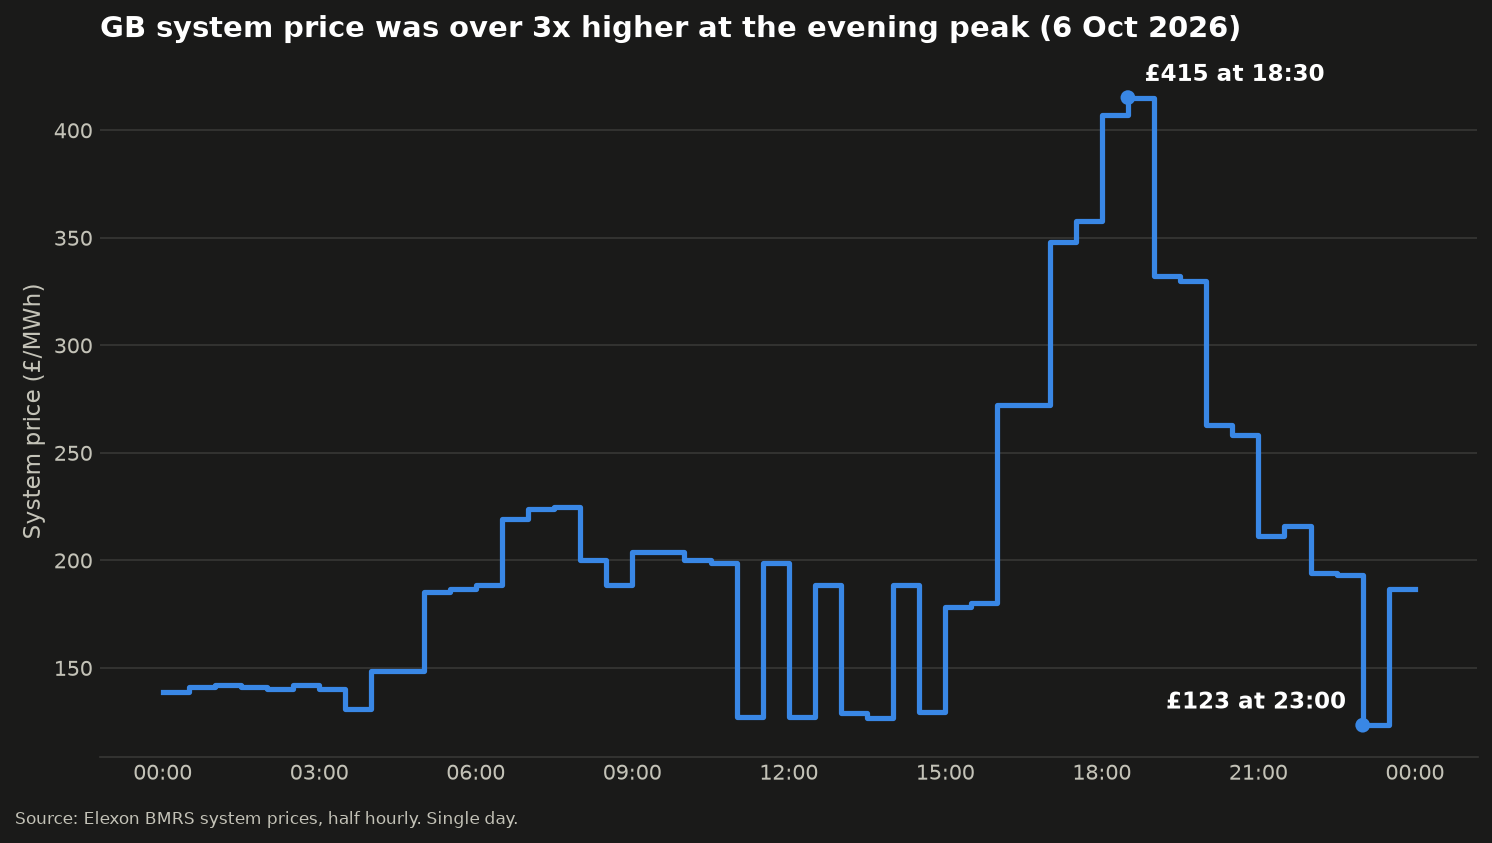

In [16]:
import json
from datetime import datetime, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# Load the latest saved fetch for 6 October
files = sorted(Path("../data/probe").glob("system_prices_2026-10-06_fetched_*.json"))
records = sorted(json.loads(files[-1].read_text())["data"], key=lambda r: r["startTime"])

# Convert start times to UK local time
uk = ZoneInfo("Europe/London")
times = [datetime.fromisoformat(r["startTime"].replace("Z", "+00:00")).astimezone(uk) for r in records]
prices = [r["systemSellPrice"] for r in records]

# Find the real high and low before adding the end point
hi = prices.index(max(prices))
lo = prices.index(min(prices))

# Add an end point at midnight so the last half hour (23:30 to 00:00) is drawn
times.append(times[-1] + timedelta(minutes=30))
prices.append(prices[-1])

# Dark theme colours
surface = "#1a1a19"
line_colour = "#3987e5"
text_primary = "#ffffff"
text_secondary = "#c3c2b7"
grid_colour = "#383835"

fig, ax = plt.subplots(figsize=(10, 5.6), dpi=150)
fig.patch.set_facecolor(surface)
ax.set_facecolor(surface)

# Step line: each price holds for its full half hour
ax.step(times, prices, where="post", color=line_colour, linewidth=2.5)

# Mark and label only the high and the low
labels = [
    (hi, f"£{prices[hi]:.0f} at {times[hi]:%H:%M}", (8, 8), "left"),
    (lo, f"£{prices[lo]:.0f} at {times[lo]:%H:%M}", (-8, 8), "right"),
]
for i, text, offset, align in labels:
    ax.scatter(times[i], prices[i], s=50, color=line_colour, edgecolor="none", zorder=3)
    ax.annotate(text, (times[i], prices[i]), xytext=offset, textcoords="offset points",
                ha=align, fontsize=11, color=text_primary, fontweight="bold")

# Titles and axes
ax.set_title("GB system price was over 3x higher at the evening peak (6 Oct 2026)",
             loc="left", fontsize=14, color=text_primary, pad=14, fontweight="bold")
ax.set_ylabel("System price (£/MWh)", color=text_secondary, fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=uk))

# Quiet grid and axes so the line stands out
ax.grid(axis="y", color=grid_colour, linewidth=0.8)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(grid_colour)
ax.tick_params(colors=text_secondary, length=0, labelsize=10)

fig.text(0.01, 0.01, "Source: Elexon BMRS system prices, half hourly. Single day.",
         fontsize=8, color=text_secondary)

fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("../data/linkedin_part1_prices_dark.png", facecolor=surface)
plt.show()

In [17]:
OM_URL = "https://single-runs-api.open-meteo.com/v1/forecast"

for run in ["2026-10-04T00:00", "2024-10-01T00:00"]:
    params = {
        "latitude": 51.5,
        "longitude": -0.13,
        "run": run,
        "models": "ecmwf_ifs",
        "hourly": "temperature_2m,shortwave_radiation,wind_speed_100m,cloud_cover",
        "timezone": "GMT",
    }
    resp = requests.get(OM_URL, params=params, timeout=60)
    print(f"Run {run} -> status {resp.status_code}")
    if resp.status_code != 200:
        print(resp.text[:500])
        continue

    body = resp.json()
    hourly = body["hourly"]
    times = hourly["time"]
    print("  Top level keys:", list(body.keys()))
    print("  Variables:", [k for k in hourly.keys() if k != "time"])
    print("  Units:", body.get("hourly_units"))
    print(f"  Hours returned: {len(times)}, from {times[0]} to {times[-1]}")
    for i in [0, 12, 36]:
        print(f"  {times[i]} | temp {hourly['temperature_2m'][i]} | solar {hourly['shortwave_radiation'][i]} "
              f"| wind100m {hourly['wind_speed_100m'][i]} | cloud {hourly['cloud_cover'][i]}")
    print()

Run 2026-10-04T00:00 -> status 200
  Top level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
  Variables: ['temperature_2m', 'shortwave_radiation', 'wind_speed_100m', 'cloud_cover']
  Units: {'time': 'iso8601', 'temperature_2m': '°C', 'shortwave_radiation': 'W/m²', 'wind_speed_100m': 'km/h', 'cloud_cover': '%'}
  Hours returned: 168, from 2026-10-04T00:00 to 2026-10-10T23:00
  2026-10-04T00:00 | temp 13.8 | solar None | wind100m 1.8 | cloud 23
  2026-10-04T12:00 | temp 19.3 | solar 508.0 | wind100m 9.3 | cloud 65
  2026-10-05T12:00 | temp 20.0 | solar 455.0 | wind100m 14.2 | cloud 35

Run 2024-10-01T00:00 -> status 200
  Top level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']
  Variables: ['temperature_2m', 'shortwave_radiation', 'wind_speed_100m', 'cloud_cover']
  Units: {'time'

In [18]:
locations = {
    "wind_off_hornsea": (53.9, 1.8),
    "wind_off_dogger": (54.8, 1.9),
    "solar_cambs": (52.3, 0.1),
    "temp_london": (51.5, -0.13),
}

params = {
    "latitude": ",".join(str(lat) for lat, _ in locations.values()),
    "longitude": ",".join(str(lon) for _, lon in locations.values()),
    "run": "2026-10-04T00:00",
    "models": "ecmwf_ifs",
    "hourly": "temperature_2m,shortwave_radiation,wind_speed_100m,cloud_cover",
    "timezone": "GMT",
}
resp = requests.get(OM_URL, params=params, timeout=60)
print("Status:", resp.status_code)
body = resp.json()
print("Response type:", type(body).__name__)

if isinstance(body, list):
    print("Number of locations returned:", len(body))
    for name, loc in zip(locations, body):
        h = loc["hourly"]
        print(f"  {name:<18} | lat {loc['latitude']:.2f} lon {loc['longitude']:.2f} "
              f"| hours {len(h['time'])} | wind100m at 12:00 {h['wind_speed_100m'][12]}")
else:
    print(json.dumps(body, indent=2)[:800])

Status: 200
Response type: list
Number of locations returned: 4
  wind_off_hornsea   | lat 53.88 lon 1.74 | hours 168 | wind100m at 12:00 28.3
  wind_off_dogger    | lat 54.80 lon 1.96 | hours 168 | wind100m at 12:00 36.5
  solar_cambs        | lat 52.27 lon 0.17 | hours 168 | wind100m at 12:00 11.6
  temp_london        | lat 51.49 lon -0.16 | hours 168 | wind100m at 12:00 9.3


In [19]:
CI_URL = "https://api.carbonintensity.org.uk"

resp = requests.get(f"{CI_URL}/intensity/2026-10-05T00:00Z/2026-10-06T00:00Z",
                    headers={"Accept": "application/json"}, timeout=30)
print("Status:", resp.status_code)
body = resp.json()
print("Top level keys:", list(body.keys()))

ci = body["data"]
print("Number of records:", len(ci))
print()
print("First record:")
print(json.dumps(ci[0], indent=2))
print()
print("Last record:")
print(json.dumps(ci[-1], indent=2))

missing_actual = sum(1 for r in ci if r["intensity"].get("actual") is None)
print()
print("Records with no actual value:", missing_actual)

Status: 200
Top level keys: ['data']
Number of records: 49

First record:
{
  "from": "2026-10-04T23:30Z",
  "to": "2026-10-05T00:00Z",
  "intensity": {
    "forecast": 105,
    "actual": 97,
    "index": "moderate"
  }
}

Last record:
{
  "from": "2026-10-05T23:30Z",
  "to": "2026-10-06T00:00Z",
  "intensity": {
    "forecast": 185,
    "actual": 184,
    "index": "high"
  }
}

Records with no actual value: 0


In [1]:
import requests
from datetime import datetime

BASE_URL = "https://data.elexon.co.uk/bmrs/api/v1"

def to_dt(s):
    return datetime.fromisoformat(s.replace("Z", "+00:00"))

url = f"{BASE_URL}/forecast/demand/day-ahead/evolution"
params = {"settlementDate": "2026-10-05", "settlementPeriod": 37, "boundary": "N", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)
resp.raise_for_status()

ev = resp.json()["data"]
print("Number of issues for this half hour:", len(ev))
print()
for r in sorted(ev, key=lambda r: r["publishTime"]):
    lead = (to_dt(r["startTime"]) - to_dt(r["publishTime"])).total_seconds() / 3600
    print(f"published {r['publishTime']} | lead {lead:5.1f} h | national {r['nationalDemand']} MW")

Status: 200
Number of issues for this half hour: 61

published 2026-10-04T07:45:00Z | lead  33.2 h | national 31020 MW
published 2026-10-04T10:48:00Z | lead  30.2 h | national 30930 MW
published 2026-10-04T11:18:00Z | lead  29.7 h | national 30930 MW
published 2026-10-04T11:48:00Z | lead  29.2 h | national 30930 MW
published 2026-10-04T12:18:00Z | lead  28.7 h | national 30930 MW
published 2026-10-04T12:48:00Z | lead  28.2 h | national 30930 MW
published 2026-10-04T13:18:00Z | lead  27.7 h | national 30930 MW
published 2026-10-04T13:48:00Z | lead  27.2 h | national 30930 MW
published 2026-10-04T14:18:00Z | lead  26.7 h | national 30930 MW
published 2026-10-04T14:48:00Z | lead  26.2 h | national 30930 MW
published 2026-10-04T15:18:00Z | lead  25.7 h | national 30930 MW
published 2026-10-04T15:47:00Z | lead  25.2 h | national 30930 MW
published 2026-10-04T16:17:00Z | lead  24.7 h | national 30930 MW
published 2026-10-04T16:47:00Z | lead  24.2 h | national 30930 MW
published 2026-10-04T17

In [2]:
url = f"{BASE_URL}/forecast/demand/day-ahead/history"
params = {"publishTime": "2026-10-04T09:00:00Z", "boundary": "N", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)
resp.raise_for_status()

hist = resp.json()["data"]
print("Number of records:", len(hist))
print("Fields:", list(hist[0].keys()))
print("Distinct publish times:", sorted({r["publishTime"] for r in hist}))

starts = sorted(r["startTime"] for r in hist)
print("Covers from:", starts[0])
print("Covers to:  ", starts[-1])

Status: 200
Number of records: 38
Fields: ['startTime', 'settlementDate', 'settlementPeriod', 'boundary', 'publishTime', 'transmissionSystemDemand', 'nationalDemand']
Distinct publish times: ['2026-10-04T08:46:00Z']
Covers from: 2026-10-04T09:00:00Z
Covers to:   2026-10-05T03:30:00Z


In [3]:
url = f"{BASE_URL}/forecast/demand/day-ahead/history"
params = {"publishTime": "2026-10-04T08:45:00Z", "boundary": "N", "format": "json"}
resp = requests.get(url, params=params, timeout=30)
print("Status:", resp.status_code)
resp.raise_for_status()

prev = resp.json()["data"]
print("Number of records:", len(prev))
print("Distinct publish times:", sorted({r["publishTime"] for r in prev}))

starts = sorted(r["startTime"] for r in prev)
print("Covers from:", starts[0])
print("Covers to:  ", starts[-1])

day_starts = [r["startTime"] for r in prev if r["settlementDate"] == "2026-10-05"]
print("Half hours of 5 Oct covered by this issue:", len(day_starts))

Status: 200
Number of records: 39
Distinct publish times: ['2026-10-04T08:16:00Z']
Covers from: 2026-10-04T08:30:00Z
Covers to:   2026-10-05T03:30:00Z
Half hours of 5 Oct covered by this issue: 10


In [4]:
from datetime import timedelta

TARGET_DAY = "2026-10-05"
as_of = datetime(2026, 10, 4, 9, 0, tzinfo=to_dt("2026-10-04T09:00:00Z").tzinfo)
chosen = {}  # settlementPeriod -> record

for step in range(1, 13):
    params = {"publishTime": as_of.strftime("%Y-%m-%dT%H:%M:%SZ"), "boundary": "N", "format": "json"}
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()
    data = resp.json()["data"]
    if not data:
        print(f"step {step}: as of {params['publishTime']} -> no data, stopping")
        break

    publish = sorted({r["publishTime"] for r in data})
    target_rows = [r for r in data if r["settlementDate"] == TARGET_DAY]
    new = 0
    for r in target_rows:
        if r["settlementPeriod"] not in chosen:
            chosen[r["settlementPeriod"]] = r
            new += 1
    print(f"step {step}: as of {params['publishTime']} -> issue {publish} | "
          f"covers {len(target_rows)} of target day | new {new} | total {len(chosen)}")

    if len(chosen) >= 48:
        break
    as_of = to_dt(publish[0]) - timedelta(minutes=1)

print()
print("Publish times used:", sorted({r["publishTime"] for r in chosen.values()}))
print("Periods covered:", len(chosen))

step 1: as of 2026-10-04T09:00:00Z -> issue ['2026-10-04T08:46:00Z'] | covers 10 of target day | new 10 | total 10
step 2: as of 2026-10-04T08:45:00Z -> issue ['2026-10-04T08:16:00Z'] | covers 10 of target day | new 0 | total 10
step 3: as of 2026-10-04T08:15:00Z -> issue ['2026-10-04T07:45:00Z'] | covers 38 of target day | new 38 | total 48

Publish times used: ['2026-10-04T07:45:00Z', '2026-10-04T08:46:00Z']
Periods covered: 48


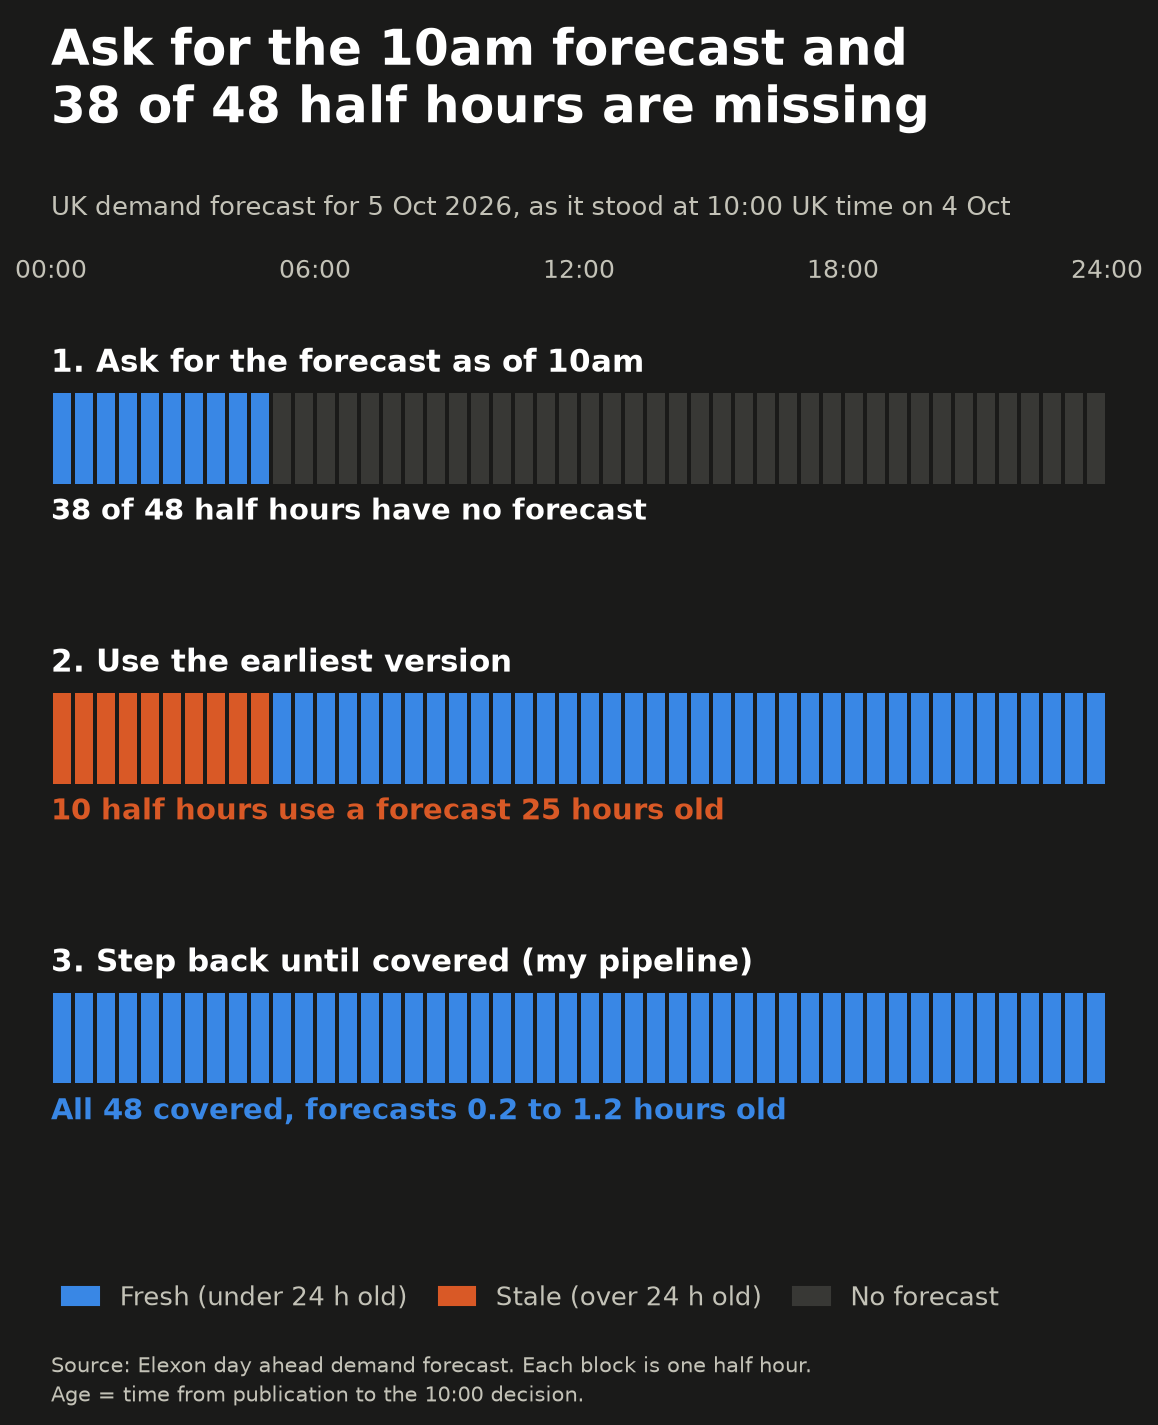

1. Ask for the forecast as of 10am -> 38 of 48 half hours have no forecast
2. Use the earliest version -> 10 half hours use a forecast 25 hours old
3. Step back until covered (my pipeline) -> All 48 covered, forecasts 0.2 to 1.2 hours old


In [11]:
from datetime import date, datetime

import matplotlib.pyplot as plt
import requests
from matplotlib.patches import Patch, Rectangle

from ukpower.config import load_settings
from ukpower.ingestion.http_client import HttpClient
from ukpower.ingestion.sources.elexon_demand_forecast import ElexonDemandForecast

s = load_settings()
BASE_URL = s.elexon.base_url
TARGET = "2026-10-05"
DECISION_UTC = datetime.fromisoformat("2026-10-04T09:00:00+00:00")  # 10:00 UK time
PERIODS = range(1, 49)
STALE_HOURS = 24


def to_dt(v):
    return datetime.fromisoformat(v.replace("Z", "+00:00"))


def first_per_period(records):
    """Map settlement period -> publish time, keeping the first one seen."""
    out = {}
    for r in records:
        if r["settlementDate"] == TARGET and r["settlementPeriod"] not in out:
            out[r["settlementPeriod"]] = to_dt(r["publishTime"])
    return out


# Approach 1: one request, forecast as of the decision time
r1 = requests.get(f"{BASE_URL}/forecast/demand/day-ahead/history",
                  params={"publishTime": "2026-10-04T09:00:00Z", "boundary": "N", "format": "json"},
                  timeout=30)
r1.raise_for_status()
as_of_once = first_per_period(r1.json()["data"])

# Approach 2: the earliest version of every half hour
r2 = requests.get(f"{BASE_URL}/forecast/demand/day-ahead/earliest",
                  params={"from": "2026-10-04T23:00Z", "to": "2026-10-05T22:30Z", "format": "json"},
                  timeout=30)
r2.raise_for_status()
earliest = first_per_period(r2.json()["data"])

# Approach 3: the pipeline's own adapter, stepping back through issues
src = ElexonDemandForecast(BASE_URL, s.tz, s.decision_time_local)
with HttpClient(s.http) as client:
    fetched = src.fetch_day(client, date(2026, 10, 5))
stepping_back = first_per_period([r for f in fetched for r in f.result.json()["data"]])

rows = [
    ("1. Ask for the forecast as of 10am", as_of_once),
    ("2. Use the earliest version", earliest),
    ("3. Step back until covered (my pipeline)", stepping_back),
]

# Leakage check: nothing used may be published after the decision
for name, mapping in rows:
    assert all(t <= DECISION_UTC for t in mapping.values()), f"leak in {name!r}"

# Colours (dark theme)
surface, text_primary, text_secondary = "#1a1a19", "#ffffff", "#c3c2b7"
fresh, stale, missing = "#3987e5", "#d95926", "#383835"


def age_hours(t):
    return (DECISION_UTC - t).total_seconds() / 3600


def colour(publish):
    if publish is None:
        return missing
    return stale if age_hours(publish) > STALE_HOURS else fresh


def summary(mapping):
    absent = sum(1 for p in PERIODS if p not in mapping)
    ages = [age_hours(t) for t in mapping.values()]
    old = sum(1 for a in ages if a > STALE_HOURS)
    if absent:
        return f"{absent} of 48 half hours have no forecast", text_primary
    if old:
        return f"{old} half hours use a forecast {max(ages):.0f} hours old", stale
    return f"All 48 covered, forecasts {min(ages):.1f} to {max(ages):.1f} hours old", fresh


missing_count = sum(1 for p in PERIODS if p not in as_of_once)

# Portrait 4:5 canvas: 8 x 10 inches at 150 dpi = 1200 x 1500 pixels
fig = plt.figure(figsize=(8, 10), dpi=150)
fig.patch.set_facecolor(surface)

fig.text(0.06, 0.955, f"Ask for the 10am forecast and\n{missing_count} of 48 half hours are missing",
         ha="left", va="top", fontsize=24, fontweight="bold", color=text_primary, linespacing=1.25)
fig.text(0.06, 0.835, "UK demand forecast for 5 Oct 2026, as it stood at 10:00 UK time on 4 Oct",
         ha="left", va="top", fontsize=12.5, color=text_secondary)

ax = fig.add_axes((0.06, 0.17, 0.88, 0.63))
ax.set_facecolor(surface)
ax.set_xlim(0, 48)
ax.set_ylim(0, 10.4)
ax.axis("off")

# Time header, shown once above the first row
for x, label in [(0, "00:00"), (12, "06:00"), (24, "12:00"), (36, "18:00"), (48, "24:00")]:
    ax.text(x, 10.0, label, ha="center", va="bottom", fontsize=12, color=text_secondary)

for i, (name, mapping) in enumerate(rows):
    base = 7.2 - i * 3.3
    ax.text(0, base + 1.75, name, ha="left", va="bottom", fontsize=15, color=text_primary,
            fontweight="bold")
    for p in PERIODS:
        ax.add_patch(Rectangle((p - 1 + 0.07, base + 0.6), 0.86, 1.0,
                               color=colour(mapping.get(p)), linewidth=0))
    text, col = summary(mapping)
    ax.text(0, base + 0.45, text, ha="left", va="top", fontsize=14, color=col, fontweight="bold")

fig.legend(handles=[Patch(color=fresh, label="Fresh (under 24 h old)"),
                    Patch(color=stale, label="Stale (over 24 h old)"),
                    Patch(color=missing, label="No forecast")],
           loc="lower left", bbox_to_anchor=(0.05, 0.075), ncol=3, frameon=False,
           labelcolor=text_secondary, fontsize=12.5, handlelength=1.4, columnspacing=1.2)

fig.text(0.06, 0.025,
         "Source: Elexon day ahead demand forecast. Each block is one half hour.\n"
         "Age = time from publication to the 10:00 decision.",
         ha="left", va="bottom", fontsize=10, color=text_secondary, linespacing=1.4)

fig.savefig("../data/linkedin_part2_forecast_coverage.png", facecolor=surface)
plt.show()

for name, mapping in rows:
    print(name, "->", summary(mapping)[0])

In [1]:
import requests

url = "https://data.elexon.co.uk/bmrs/api/v1/generation/actual/per-type/wind-and-solar"
params = {
    "from": "2025-09-16",
    "to": "2025-09-16",
    "settlementPeriodFrom": 1,
    "settlementPeriodTo": 50,
    "format": "json",
}
rows = requests.get(url, params=params, timeout=30).json()["data"]
print("total records:", len(rows))
for r in rows:
    if r["settlementPeriod"] == 18:
        print(r)

total records: 147
{'publishTime': '2025-09-16T14:10:24Z', 'businessType': 'Wind generation', 'psrType': 'Wind Onshore', 'quantity': 5383.019, 'startTime': '2025-09-16T07:30:00Z', 'settlementDate': '2025-09-16', 'settlementPeriod': 18}
{'publishTime': '2025-09-16T14:10:24Z', 'businessType': 'Wind generation', 'psrType': 'Wind Offshore', 'quantity': 11516.169, 'startTime': '2025-09-16T07:30:00Z', 'settlementDate': '2025-09-16', 'settlementPeriod': 18}
{'publishTime': '2025-09-16T14:10:24Z', 'businessType': 'Solar generation', 'psrType': 'Solar', 'quantity': 3267.0, 'startTime': '2025-09-16T07:30:00Z', 'settlementDate': '2025-09-16', 'settlementPeriod': 18}
{'publishTime': '2025-09-16T09:58:22Z', 'businessType': 'Wind generation', 'psrType': 'Wind Onshore', 'quantity': 5383.019, 'startTime': '2025-09-16T07:30:00Z', 'settlementDate': '2025-09-16', 'settlementPeriod': 18}
{'publishTime': '2025-09-16T09:58:22Z', 'businessType': 'Wind generation', 'psrType': 'Wind Offshore', 'quantity': 1151

In [2]:
url = "https://data.elexon.co.uk/bmrs/api/v1/forecast/generation/wind-and-solar/day-ahead"
params = {
    "from": "2026-04-26",
    "to": "2026-04-26",
    "settlementPeriodFrom": 1,
    "settlementPeriodTo": 50,
    "processType": "day ahead",
    "format": "json",
}
rows = requests.get(url, params=params, timeout=30).json()["data"]
print("total records:", len(rows))
for r in rows:
    if r["settlementPeriod"] == 10:
        print(r)

total records: 288
{'publishTime': '2026-04-25T16:45:04Z', 'processType': 'Day ahead', 'businessType': 'Solar generation', 'psrType': 'Solar', 'startTime': '2026-04-26T03:30:00Z', 'settlementDate': '2026-04-26', 'settlementPeriod': 10, 'quantity': 0.0}
{'publishTime': '2026-04-25T16:45:04Z', 'processType': 'Day ahead', 'businessType': 'Wind generation', 'psrType': 'Wind Offshore', 'startTime': '2026-04-26T03:30:00Z', 'settlementDate': '2026-04-26', 'settlementPeriod': 10, 'quantity': 1451.615}
{'publishTime': '2026-04-25T16:45:04Z', 'processType': 'Day ahead', 'businessType': 'Wind generation', 'psrType': 'Wind Onshore', 'startTime': '2026-04-26T03:30:00Z', 'settlementDate': '2026-04-26', 'settlementPeriod': 10, 'quantity': 438.382}
{'publishTime': '2026-04-25T16:45:04Z', 'processType': 'Day ahead', 'businessType': 'Wind generation', 'psrType': 'Wind Offshore', 'startTime': '2026-04-26T03:30:00Z', 'settlementDate': '2026-04-26', 'settlementPeriod': 10, 'quantity': 2902.938}
{'publishTi

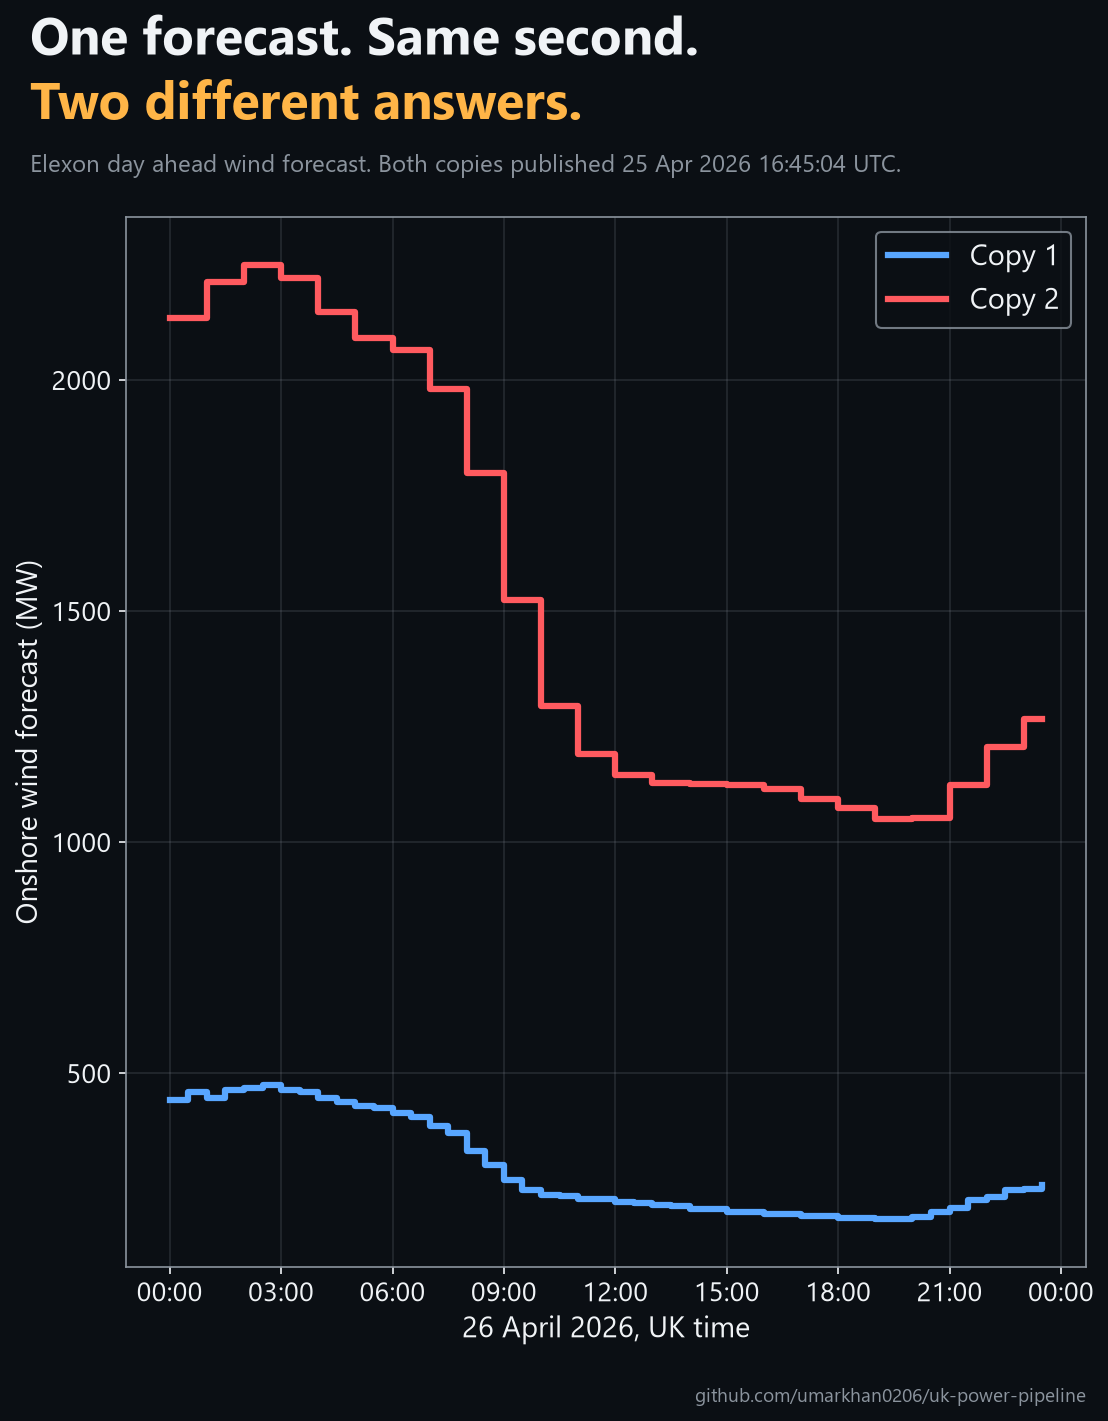

In [7]:
import requests
from collections import defaultdict
from datetime import datetime
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Segoe UI", "DejaVu Sans"]

UK = ZoneInfo("Europe/London")
url = "https://data.elexon.co.uk/bmrs/api/v1/forecast/generation/wind-and-solar/day-ahead"
params = {"from": "2026-04-26", "to": "2026-04-26", "settlementPeriodFrom": 1,
          "settlementPeriodTo": 50, "processType": "day ahead", "format": "json"}
rows = requests.get(url, params=params, timeout=30).json()["data"]

# Split into copy 1 and copy 2: first and second time each (period, type) appears
seen = defaultdict(int)
copies = {1: {}, 2: {}}
for r in rows:
    key = (r["settlementPeriod"], r["psrType"])
    seen[key] += 1
    if r["psrType"] == "Wind Onshore" and seen[key] <= 2:
        t = datetime.fromisoformat(r["startTime"].replace("Z", "+00:00")).astimezone(UK)
        copies[seen[key]][t] = r["quantity"]

times = sorted(copies[1])
a = [copies[1][t] for t in times]
b = [copies[2][t] for t in times]

# Same colours as the health map
BG, FG, GREY = "#0b0f14", "#f0f3f6", "#8b949e"
AMBER, RED, BLUE = "#ffb547", "#ff5a5f", "#58a6ff"

fig = plt.figure(figsize=(8, 10), dpi=150)
fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.14, 0.12, 0.80, 0.70])
ax.set_facecolor(BG)
ax.step(times, a, where="post", color=BLUE, lw=3, label="Copy 1")
ax.step(times, b, where="post", color=RED, lw=3, label="Copy 2")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=UK))
ax.tick_params(colors=FG, labelsize=13)
for s in ax.spines.values():
    s.set_color(GREY)
ax.set_ylabel("Onshore wind forecast (MW)", color=FG, fontsize=14)
ax.set_xlabel("26 April 2026, UK time", color=FG, fontsize=14)
ax.legend(fontsize=14, facecolor=BG, edgecolor=GREY, labelcolor=FG, loc="upper right")
ax.grid(color=GREY, alpha=0.2)

fig.text(0.06, 0.955, "One forecast. Same second.", color=FG, fontsize=25,
         fontweight="bold", va="top")
fig.text(0.06, 0.912, "Two different answers.", color=AMBER, fontsize=25,
         fontweight="bold", va="top")
fig.text(0.06, 0.862, "Elexon day ahead wind forecast. Both copies published "
         "25 Apr 2026 16:45:04 UTC.", color=GREY, fontsize=11.5, va="top")
fig.text(0.94, 0.03, "github.com/umarkhan0206/uk-power-pipeline", color=GREY, fontsize=9,
         ha="right")

fig.savefig("../data/linkedin_part3_conflicting_forecast.png", facecolor=BG)
plt.show()

days per source: 743 | cells: 6687
clean: 6620 | revised: 61 | missing: 6
  System prices                clean  743  revised   0  missing  0
  Demand, actual               clean  743  revised   0  missing  0
  Generation by fuel           clean  743  revised   0  missing  0
  Wind and solar, actual       clean  686  revised  57  missing  0
  Carbon intensity             clean  743  revised   0  missing  0
  Demand forecast              clean  743  revised   0  missing  0
  Wind forecast                clean  743  revised   0  missing  0
  Wind and solar, day ahead    clean  737  revised   4  missing  2
  Weather forecast, ECMWF      clean  739  revised   0  missing  4


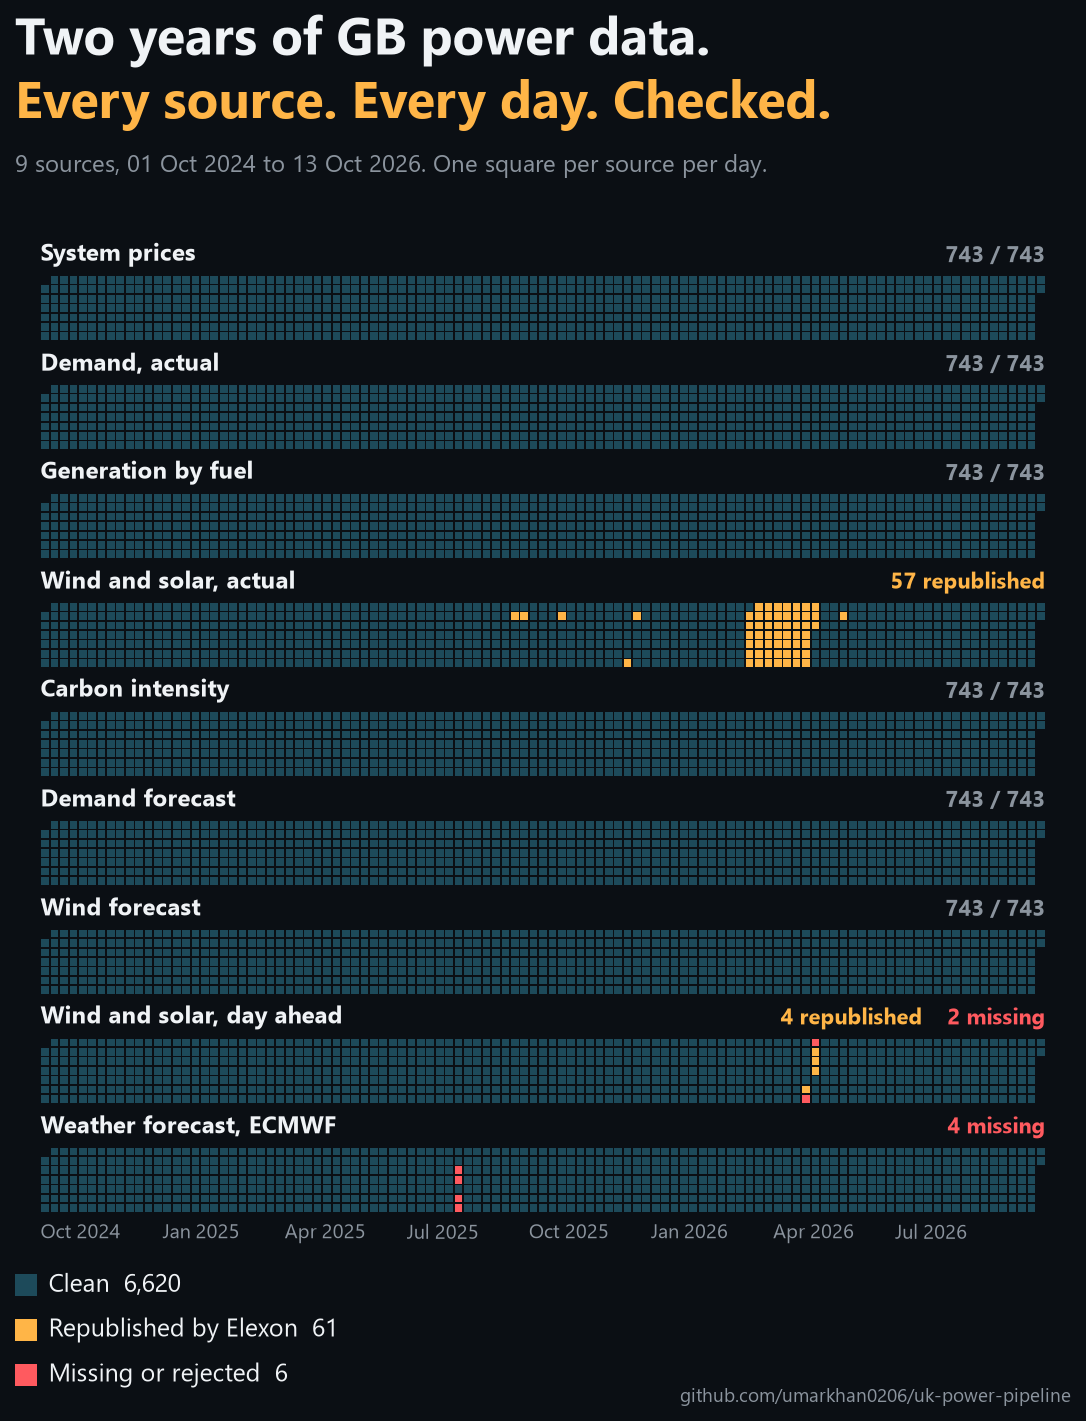

In [5]:
import json
from collections import defaultdict
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

plt.rcParams["font.family"] = ["Segoe UI", "DejaVu Sans"]

LANDING = Path("../data/landing")
OUT = Path("../data/linkedin_part3_health_map.png")
START, END = date(2024, 10, 1), date(2026, 10, 13)

# (folder name, label on the chart), top to bottom
ROWS = [
    ("elexon_system_prices", "System prices"),
    ("elexon_demand_outturn", "Demand, actual"),
    ("elexon_generation_by_fuel", "Generation by fuel"),
    ("elexon_wind_solar_actual", "Wind and solar, actual"),
    ("carbon_intensity", "Carbon intensity"),
    ("elexon_demand_forecast", "Demand forecast"),
    ("elexon_wind_forecast", "Wind forecast"),
    ("elexon_wind_solar_day_ahead", "Wind and solar, day ahead"),
    ("open_meteo_ecmwf", "Weather forecast, ECMWF"),
]
# Sources where one half hour can legitimately appear with several publish times
REVISION_SOURCES = {"elexon_wind_solar_actual", "elexon_wind_solar_day_ahead"}


def day_status(source: str, day: date) -> str:
    folder = LANDING / source / day.isoformat()
    files = [f for f in folder.glob("*.json") if not f.name.endswith(".meta.json")]
    if not files:
        return "missing"
    if source in REVISION_SOURCES:
        versions = defaultdict(set)
        for f in files:
            for r in json.loads(f.read_text(encoding="utf-8"))["data"]:
                versions[(r["settlementPeriod"], r["psrType"])].add(r["publishTime"])
        if any(len(v) > 1 for v in versions.values()):
            return "revised"
    return "clean"


days = [START + timedelta(d) for d in range((END - START).days + 1)]
status = {src: {d: day_status(src, d) for d in days} for src, _ in ROWS}
totals = defaultdict(int)
for src, _ in ROWS:
    for s in status[src].values():
        totals[s] += 1
print("days per source:", len(days), "| cells:", len(days) * len(ROWS))
print("clean:", totals["clean"], "| revised:", totals["revised"], "| missing:", totals["missing"])
for src, label in ROWS:
    c = defaultdict(int)
    for s in status[src].values():
        c[s] += 1
    print(f"  {label:<28} clean {c['clean']:>4}  revised {c['revised']:>3}  missing {c['missing']:>2}")

# Colours: calm base so the problems stand out
BG, FG, GREY = "#0b0f14", "#f0f3f6", "#8b949e"
COLOURS = {"clean": "#1d4a5a", "revised": "#ffb547", "missing": "#ff5a5f"}

first_monday = START - timedelta(START.weekday())
week = lambda d: (d - first_monday).days // 7  # noqa: E731
n_weeks = week(END) + 1
STRIP, GAP = 7, 4.6  # 7 weekdays per strip, space above each strip for its label

fig = plt.figure(figsize=(8, 10), dpi=150)
fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.06, 0.13, 0.88, 0.68])
ax.set_facecolor(BG)

patches, colours = [], []
for i, (src, label) in enumerate(ROWS):
    top = i * (STRIP + GAP) + GAP
    for d in days:
        patches.append(Rectangle((week(d) + 0.09, top + d.weekday() + 0.09), 0.82, 0.82))
        colours.append(COLOURS[status[src][d]])
    ax.text(0, top - 0.9, label, color=FG, fontsize=11.5, fontweight="bold", va="bottom")
    c = defaultdict(int)
    for s in status[src].values():
        c[s] += 1
    notes = []
    if c["revised"]:
        notes.append((f"{c['revised']} republished", COLOURS["revised"]))
    if c["missing"]:
        notes.append((f"{c['missing']} missing", COLOURS["missing"]))
    if not notes:
        notes.append((f"{c['clean']} / {len(days)}", GREY))
    anchor = None
    for text, col in reversed(notes):
        style = dict(color=col, fontsize=10.5, ha="right", va="bottom", fontweight="bold")
        if anchor is None:
            anchor = ax.text(n_weeks, top - 0.9, text, **style)
        else:
            anchor = ax.annotate(text, xy=(0, 0), xycoords=anchor, xytext=(-12, 0),
                                 textcoords="offset points", **style)
ax.add_collection(PatchCollection(patches, facecolors=colours, edgecolors="none"))

# Month markers under the last strip
bottom = len(ROWS) * (STRIP + GAP) + 1.2
for d in days:
    if d.day == 1 and d.month in (1, 4, 7, 10) and week(d) < n_weeks - 8:
        ax.text(week(d), bottom, d.strftime("%b %Y"), color=GREY, fontsize=9.5, va="top")

ax.set_xlim(-0.2, n_weeks + 0.2)
ax.set_ylim(bottom + 3, 0)
ax.set_aspect("equal")
ax.axis("off")

fig.text(0.06, 0.955, "Two years of GB power data.", color=FG, fontsize=25,
         fontweight="bold", va="top")
fig.text(0.06, 0.912, "Every source. Every day. Checked.", color=COLOURS["revised"],
         fontsize=25, fontweight="bold", va="top")
fig.text(0.06, 0.862, f"9 sources, {START:%d %b %Y} to {END:%d %b %Y}. One square per source per day.",
         color=GREY, fontsize=11.5, va="top")

legend = [
    ("clean", f"Clean  {totals['clean']:,}"),
    ("revised", f"Republished by Elexon  {totals['revised']:,}"),
    ("missing", f"Missing or rejected  {totals['missing']:,}"),
]
y = 0.105
for key, text in legend:
    fig.patches.append(Rectangle((0.06, y - 0.004), 0.018, 0.0144, transform=fig.transFigure,
                                 facecolor=COLOURS[key], edgecolor="none"))
    fig.text(0.088, y + 0.003, text, color=FG, fontsize=12, va="center")
    y -= 0.03
fig.text(0.94, 0.03, "github.com/umarkhan0206/uk-power-pipeline", color=GREY, fontsize=9,
         ha="right")

fig.savefig(OUT, facecolor=BG)
plt.show()

In [1]:
import requests

url = "https://data.elexon.co.uk/bmrs/api/v1/generation/actual/per-type/wind-and-solar"
for day in ["2024-12-04", "2026-05-21"]:
    params = {"from": day, "to": day, "settlementPeriodFrom": 1,
              "settlementPeriodTo": 50, "format": "json"}
    rows = requests.get(url, params=params, timeout=30).json()["data"]
    periods = sorted({r["settlementPeriod"] for r in rows})
    missing = sorted(set(range(1, 49)) - set(periods))
    print(f"{day}: {len(rows)} records, {len(periods)} periods, missing {missing}")

2024-12-04: 114 records, 38 periods, missing [17, 18, 19, 20, 21, 22, 23, 24, 25, 27]
2026-05-21: 72 records, 24 periods, missing [1, 2, 3, 4, 5, 6, 7, 9, 11, 13, 18, 19, 20, 21, 23, 24, 25, 26, 29, 33, 35, 37, 46, 47]


In [1]:
import requests

base = "https://single-runs-api.open-meteo.com/v1/forecast"
params = {"latitude": 51.5, "longitude": -0.13, "run": "2025-10-25T00:00",
          "models": "ecmwf_ifs", "hourly": "temperature_2m", "timezone": "GMT"}

for extra in [{}, {"forecast_days": 3}, {"forecast_hours": 72}]:
    r = requests.get(base, params={**params, **extra}, timeout=30)
    body = r.json()
    times = body.get("hourly", {}).get("time", [])
    print(extra or "no setting", "| status", r.status_code, "| hours", len(times),
          "| first", times[0] if times else None, "| last", times[-1] if times else None,
          "| error", body.get("reason"))

no setting | status 200 | hours 168 | first 2025-10-25T00:00 | last 2025-10-31T23:00 | error None
{'forecast_days': 3} | status 200 | hours 72 | first 2025-10-25T00:00 | last 2025-10-27T23:00 | error None
{'forecast_hours': 72} | status 200 | hours 72 | first 2025-10-25T00:00 | last 2025-10-27T23:00 | error None


In [3]:
import time
import requests
from datetime import date, datetime, timedelta, UTC

base = "https://single-runs-api.open-meteo.com/v1/forecast"
bad_days = [date(2025, 8, 6), date(2025, 8, 7), date(2025, 8, 8),
            date(2025, 8, 9), date(2025, 8, 10), date(2026, 6, 24)]


def get_json(params, attempts=4):
    """Retry dropped connections a few times, waiting a little longer each time."""
    for attempt in range(1, attempts + 1):
        try:
            return requests.get(base, params=params, timeout=30).json()
        except requests.ConnectionError:
            if attempt == attempts:
                raise
            time.sleep(5 * attempt)


for day in bad_days:
    target_start = datetime(day.year, day.month, day.day, tzinfo=UTC) - timedelta(hours=1)
    print(f"\nTarget day {day}")
    for back_hours in [0, 6, 12, 18, 24]:  # 0 = the normal run (00:00 UTC the day before)
        run = datetime(day.year, day.month, day.day, tzinfo=UTC) - timedelta(days=1, hours=back_hours)
        params = {"latitude": 51.5, "longitude": -0.13, "run": run.strftime("%Y-%m-%dT%H:%M"),
                  "models": "ecmwf_ifs", "hourly": "temperature_2m,shortwave_radiation",
                  "timezone": "GMT", "forecast_days": 4}
        body = get_json(params)
        time.sleep(1)  # be polite to the free service
        if body.get("error"):
            print(f"  run {run:%Y-%m-%d %H:%M}: not available")
            continue
        h = body["hourly"]
        idx = [i for i, t in enumerate(h["time"]) if t >= target_start.strftime("%Y-%m-%dT%H:%M")][:24]
        blanks = {v: sum(h[v][i] is None for i in idx) for v in ["temperature_2m", "shortwave_radiation"]}
        print(f"  run {run:%Y-%m-%d %H:%M}: available, {len(idx)} target hours, blanks {blanks}")


Target day 2025-08-06
  run 2025-08-05 00:00: not available
  run 2025-08-04 18:00: not available
  run 2025-08-04 12:00: available, 24 target hours, blanks {'temperature_2m': 24, 'shortwave_radiation': 0}
  run 2025-08-04 06:00: available, 24 target hours, blanks {'temperature_2m': 0, 'shortwave_radiation': 0}
  run 2025-08-04 00:00: available, 24 target hours, blanks {'temperature_2m': 0, 'shortwave_radiation': 0}

Target day 2025-08-07
  run 2025-08-06 00:00: not available
  run 2025-08-05 18:00: available, 24 target hours, blanks {'temperature_2m': 0, 'shortwave_radiation': 24}
  run 2025-08-05 12:00: available, 24 target hours, blanks {'temperature_2m': 24, 'shortwave_radiation': 24}
  run 2025-08-05 06:00: not available
  run 2025-08-05 00:00: not available

Target day 2025-08-08
  run 2025-08-07 00:00: available, 24 target hours, blanks {'temperature_2m': 24, 'shortwave_radiation': 24}
  run 2025-08-06 18:00: available, 24 target hours, blanks {'temperature_2m': 24, 'shortwave_

In [4]:
VARS4 = "temperature_2m,shortwave_radiation,wind_speed_100m,cloud_cover"

for day in [date(2025, 8, 7), date(2025, 8, 8)]:
    target_start = datetime(day.year, day.month, day.day, tzinfo=UTC) - timedelta(hours=1)
    print(f"\nTarget day {day}")
    for back_hours in range(24, 49, 6):  # 24 to 48 hours before the normal run
        run = datetime(day.year, day.month, day.day, tzinfo=UTC) - timedelta(days=1, hours=back_hours)
        params = {"latitude": 51.5, "longitude": -0.13, "run": run.strftime("%Y-%m-%dT%H:%M"),
                  "models": "ecmwf_ifs", "hourly": VARS4, "timezone": "GMT", "forecast_days": 5}
        body = get_json(params)
        time.sleep(1)
        if body.get("error"):
            print(f"  run {run:%Y-%m-%d %H:%M}: not available")
            continue
        h = body["hourly"]
        idx = [i for i, t in enumerate(h["time"]) if t >= target_start.strftime("%Y-%m-%dT%H:%M")][:24]
        blanks = {v: sum(h[v][i] is None for i in idx) for v in VARS4.split(",")}
        print(f"  run {run:%Y-%m-%d %H:%M}: {len(idx)} hours, blanks {blanks}")


Target day 2025-08-07
  run 2025-08-05 00:00: not available
  run 2025-08-04 18:00: not available
  run 2025-08-04 12:00: 24 hours, blanks {'temperature_2m': 24, 'shortwave_radiation': 0, 'wind_speed_100m': 24, 'cloud_cover': 24}
  run 2025-08-04 06:00: 24 hours, blanks {'temperature_2m': 0, 'shortwave_radiation': 0, 'wind_speed_100m': 0, 'cloud_cover': 0}
  run 2025-08-04 00:00: 24 hours, blanks {'temperature_2m': 0, 'shortwave_radiation': 0, 'wind_speed_100m': 0, 'cloud_cover': 0}

Target day 2025-08-08
  run 2025-08-06 00:00: not available
  run 2025-08-05 18:00: 24 hours, blanks {'temperature_2m': 0, 'shortwave_radiation': 24, 'wind_speed_100m': 24, 'cloud_cover': 0}
  run 2025-08-05 12:00: 24 hours, blanks {'temperature_2m': 24, 'shortwave_radiation': 24, 'wind_speed_100m': 24, 'cloud_cover': 0}
  run 2025-08-05 06:00: not available
  run 2025-08-05 00:00: not available


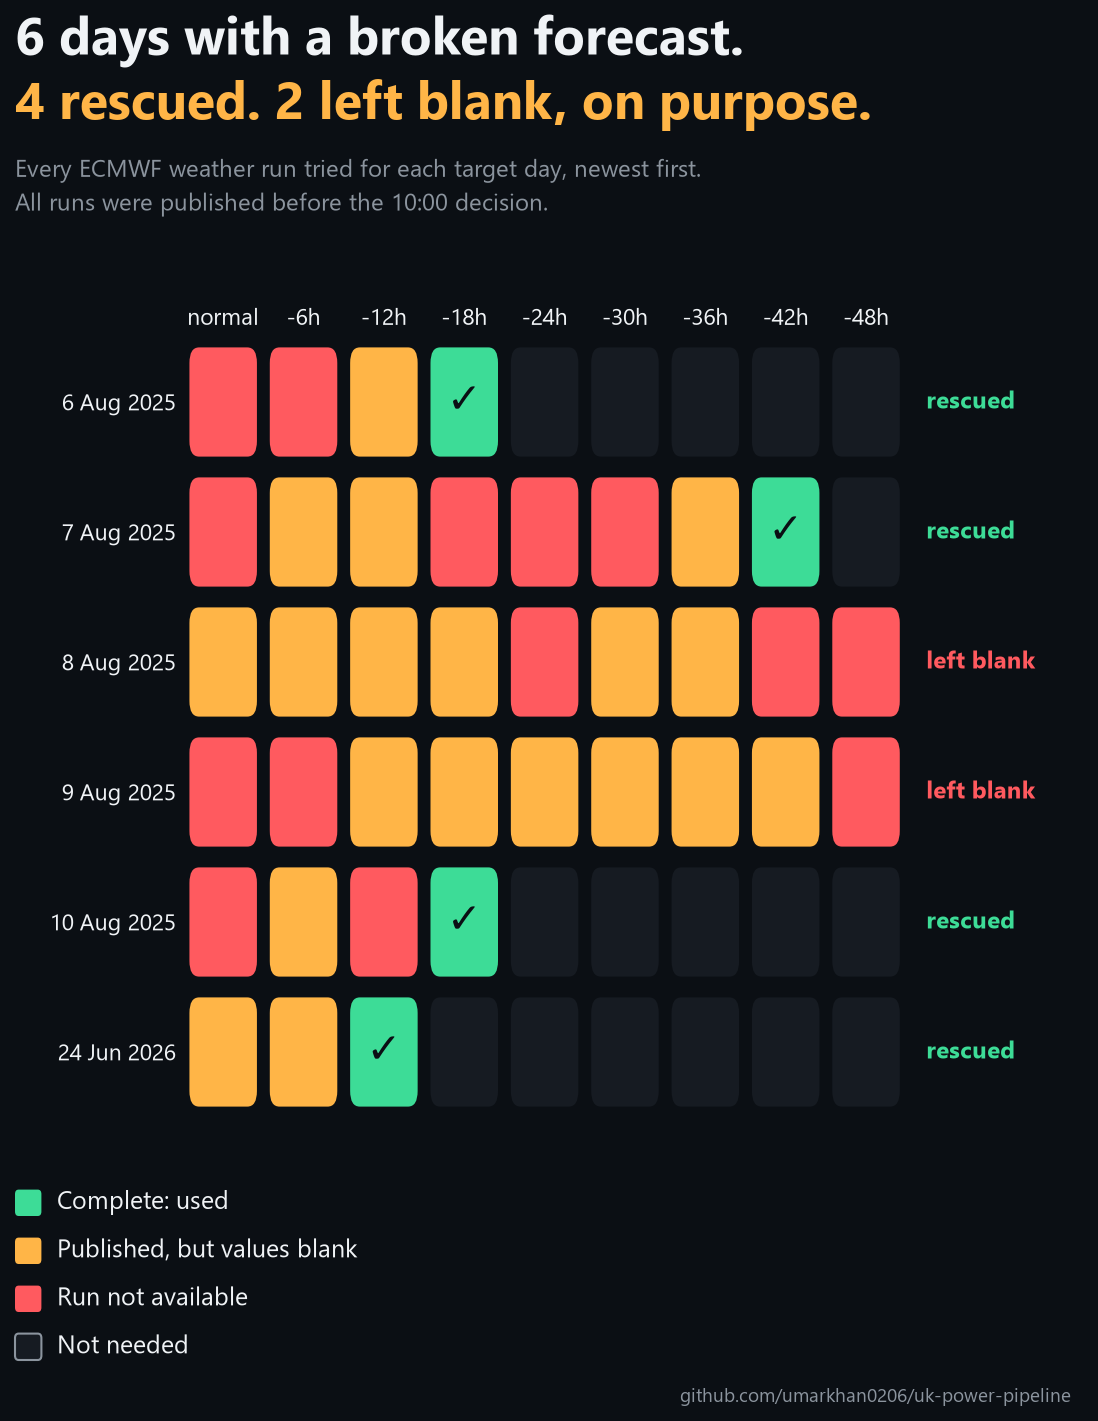

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams["font.family"] = ["Segoe UI", "DejaVu Sans"]
BG, FG, GREY = "#0b0f14", "#f0f3f6", "#8b949e"
COL = {"used": "#3ddc97", "incomplete": "#ffb547", "missing": "#ff5a5f", "untried": "#161b22"}

# From the backfill log of 18 Oct 2026. Columns: the normal run, then 6 h earlier each step.
U, I, M, N = "used", "incomplete", "missing", "untried"
rows = [
    ("6 Aug 2025",  [M, M, I, U, N, N, N, N, N]),
    ("7 Aug 2025",  [M, I, I, M, M, M, I, U, N]),
    ("8 Aug 2025",  [I, I, I, I, M, I, I, M, M]),
    ("9 Aug 2025",  [M, M, I, I, I, I, I, I, M]),
    ("10 Aug 2025", [M, I, M, U, N, N, N, N, N]),
    ("24 Jun 2026", [I, I, U, N, N, N, N, N, N]),
]
cols = ["normal", "-6h", "-12h", "-18h", "-24h", "-30h", "-36h", "-42h", "-48h"]

fig = plt.figure(figsize=(8, 10), dpi=150)
fig.patch.set_facecolor(BG)
ax = fig.add_axes([0.20, 0.22, 0.75, 0.52])
ax.set_facecolor(BG)
for r, (_, cells) in enumerate(rows):
    for c, state in enumerate(cells):
        ax.add_patch(FancyBboxPatch((c + 0.08, r + 0.08), 0.84, 0.84,
                                    boxstyle="round,pad=0,rounding_size=0.12",
                                    facecolor=COL[state], edgecolor="none"))
        if state == "used":
            ax.text(c + 0.5, r + 0.5, "✓", color=BG, fontsize=20, ha="center", va="center",
                    fontweight="bold")
    result = "rescued" if "used" in cells else "left blank"
    ax.text(9.25, r + 0.5, result, color=COL["used"] if result == "rescued" else COL["missing"],
            fontsize=11.5, va="center", fontweight="bold")
ax.set_xlim(0, 11.2)
ax.set_ylim(len(rows), 0)
ax.set_yticks([r + 0.5 for r in range(len(rows))], [d for d, _ in rows])
ax.set_xticks([c + 0.5 for c in range(len(cols))], cols)
ax.tick_params(colors=FG, labelsize=11, length=0)
ax.xaxis.tick_top()
for s in ax.spines.values():
    s.set_visible(False)

fig.text(0.06, 0.955, "6 days with a broken forecast.", color=FG, fontsize=25,
         fontweight="bold", va="top")
fig.text(0.06, 0.912, "4 rescued. 2 left blank, on purpose.", color=COL["incomplete"],
         fontsize=25, fontweight="bold", va="top")
fig.text(0.06, 0.862, "Every ECMWF weather run tried for each target day, newest first.\n"
         "All runs were published before the 10:00 decision.",
         color=GREY, fontsize=11.5, va="top", linespacing=1.5)

legend = [("used", "Complete: used"), ("incomplete", "Published, but values blank"),
          ("missing", "Run not available"), ("untried", "Not needed")]
y = 0.16
for key, label in legend:
    fig.patches.append(FancyBboxPatch((0.06, y - 0.006), 0.022, 0.0176,
                                      boxstyle="round,pad=0,rounding_size=0.003",
                                      transform=fig.transFigure, facecolor=COL[key],
                                      edgecolor=GREY if key == "untried" else "none"))
    fig.text(0.095, y + 0.003, label, color=FG, fontsize=12, va="center")
    y -= 0.032
fig.text(0.94, 0.03, "github.com/umarkhan0206/uk-power-pipeline", color=GREY, fontsize=9,
         ha="right")

fig.savefig("../data/linkedin_part4_weather_fallback.png", facecolor=BG)
plt.show()